In [1]:
from langgraph.graph import StateGraph
from typing import TypedDict, Annotated
from langchain_ollama import ChatOllama
from langchain_core.prompts import PromptTemplate
from pydantic import BaseModel, Field
import operator
from langgraph.constants import START, END

In [2]:
model= ChatOllama(
    model="qwen2.5-coder:3b", temperature=0.3
)

In [3]:
class AnalysisSchema(BaseModel):
    feedback: str = Field(description="Detailed feedback of the essay")
    score: int = Field(description="Score out of 0 to 10", ge=0, le=10)

class SummarySchema(BaseModel):
    feedback: str = Field(description="summary of the essay based on clarity , depth and language feedback")

In [4]:
structured_model= model.with_structured_output(AnalysisSchema)
summary_model= model.with_structured_output(SummarySchema)

In [5]:
class EssayState(TypedDict):
    essay_text: str
    clarity: str
    depth: str
    language: str
    overall: str
    individual_score: Annotated[list[int], operator.add] #reducer functions so that we can add/merge the scores to this variable in parallel
    avg_score: float

In [6]:
bad_essay= """
Social media is everywhere today and everybody is on phone whole day. I think social media has lots of stuff going on. People use instagram and facebook and tiktok to scroll videos and post pictures. It is good because you can see what your friend is doing and message them anytime. Also funny videos make people laugh when they are sad or bore. 
But social media is also very bad thing for people. Many people just waste time and don't do study or job. They just watch reels for hours and hours. Also people fight in comment section for no reason and say bad words to each other. This makes bad mentality. Sometimes people see rich people pictures and feel jealous and think their own life is bad, which is not good for brain health.
In conclusion social media has two sides, one good side and one bad side. We should not use phone too much and go outside more. Government and parents should tell kids to stop using it so much otherwise future will be in trouble. So social media is both useful and dangerous.
"""


good_essay= """
# Algorithmic Connectivity: Examining the Societal Architecture of Social Media
The emergence of digital social platforms represents one of the most consequential cultural shifts of the twenty-first century. By democratizing information distribution and enabling instantaneous global communication, social media has dismantled traditional geographic barriers. However, beneath the promise of borderless connection lies an attention-driven business model engineered to maximize user engagement through algorithmic amplification. Consequently, social media operates as a double-edged sword: empowering grassroots mobilization while simultaneously fragmenting civic discourse and exacerbating psychological vulnerabilities.
At an institutional and communal level, decentralized platforms have fundamentally transformed public participation. Grassroots political movements, independent journalism, and marginalized communities can now bypass legacy media gatekeepers to organize coalitions and elevate neglected issues to global prominence. During humanitarian crises and public health emergencies, social networks facilitate rapid coordination of mutual aid and vital resource dissemination. Furthermore, niche digital communities provide essential emotional and professional solidarity for individuals who may experience geographic or cultural isolation in their physical environments.
Conversely, the algorithmic mechanisms underpinning these platforms prioritize content that elicits high emotional arousal, frequently rewarding polarization over nuanced deliberation. Sensationalism, misinformation, and partisan outrage are systematically favored by recommendation algorithms designed to increase watch-time and ad revenue. This dynamic fosters epistemological echo chambers, eroding shared factual realities and deepening social balkanization. On an individual level, the commodification of social validation—quantified through follower counts, likes, and algorithmic metrics—has been strongly linked to heightened rates of anxiety, depressive symptoms, and cognitive fatigue, particularly among adolescents vulnerable to social comparison.
In conclusion, the societal trajectory of social media cannot be remedied through binary categorizations of absolute rejection or passive acceptance. Rather, addressing its deleterious consequences requires systemic interventions: transparent algorithmic auditing, robust data privacy regulations, and comprehensive digital literacy curricula that equip users to critically navigate information ecosystems. Only by subordinating algorithmic engagement metrics to human well-being can society preserve the democratic benefits of digital connection while mitigating its systemic harms.
"""

In [11]:
def clarity_feedback(state: EssayState):
    essay= state["essay_text"]
    prompt= PromptTemplate(
        template="""
        You are a strict academic evaluator. 
        Evaluate the essay below on Clarity and assign an integer score from 0 to 10 using this rubric:
        - 0 to 4: Confusing, disjointed, highly repetitive, or informal.
        - 5 to 7: Understandable but lacks smooth transitions and structure.
        - 8 to 10: Exceptionally well-structured, coherent, and articulate.
        Essay:
        {essay}
        """,
        input_variables=["essay"]
    )

    chain= prompt | structured_model

    response= chain.invoke({"essay":essay})

    return {"clarity": response.feedback , "individual_score": [response.score]}

def depth_feedback(state: EssayState):
    essay= state["essay_text"]
    prompt= PromptTemplate(
        template="Give a feedback on the basis of depth of the essay and assign a score out of 0 to 10 from the given essay \n {essay}",
        input_variables=["essay"]
    )

    chain= prompt | structured_model

    response= chain.invoke({"essay":essay})

    return {"depth": response.feedback , "individual_score": [response.score]}

def language_feedback(state: EssayState):
    essay= state["essay_text"]
    prompt= PromptTemplate(
        template="Give a feedback on the basis of language of the essay and assign a score out of 0 to 10 from the given essay \n {essay}",
        input_variables=["essay"]
    )

    chain= prompt | structured_model

    response= chain.invoke({"essay":essay})

    return {"language": response.feedback , "individual_score": [response.score]}

def summary_feedback(state: EssayState):
    clarity_feedback= state["clarity"]
    depth_feedback= state["depth"]
    language_feedback= state["language"]


    # single summary
    prompt= PromptTemplate(
        template="Give a single summary of the essay based on clarity of thought feedback : {clarity_feedback}, depth feedback : {depth_feedback} and language feedback : {language_feedback}",
        input_variables=["clarity_feedback", "depth_feedback", "language_feedback"]
    )

    chain= prompt | summary_model

    response= chain.invoke({"clarity_feedback":clarity_feedback, "depth_feedback": depth_feedback, "language_feedback": language_feedback})

    # avg score
    avg_score= sum(state["individual_score"])/len(state["individual_score"])

    return {"overall": response.feedback , "avg_score": avg_score}

In [12]:
graph= StateGraph(EssayState)

graph.add_node("clarity_feedback",clarity_feedback)
graph.add_node("depth_feedback",depth_feedback)
graph.add_node("language_feedback",language_feedback)
graph.add_node("summary_feedback",summary_feedback)


graph.add_edge(START,"clarity_feedback")
graph.add_edge(START,"depth_feedback")
graph.add_edge(START,"language_feedback")

graph.add_edge("clarity_feedback", "summary_feedback")
graph.add_edge("depth_feedback", "summary_feedback")
graph.add_edge("language_feedback", "summary_feedback")

graph.add_edge("summary_feedback", END)

workflow= graph.compile()

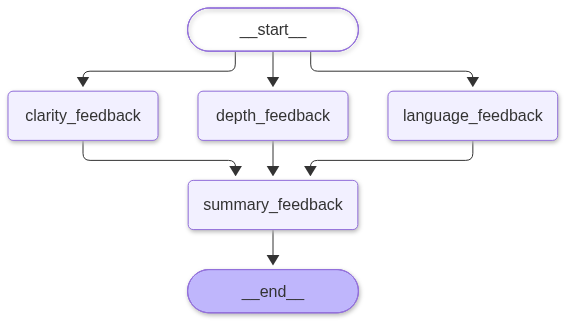

In [13]:
workflow

In [14]:
# Test the bad essay:
state_bad = workflow.invoke({"essay_text": bad_essay})
print("=== BAD ESSAY EVALUATION ===")
print(f"Average Score: {state_bad['avg_score']:.1f}")
print(f"Clarity: {state_bad['clarity']}")
print(f"Depth: {state_bad['depth']}")
print(f"Language: {state_bad['language']}")
print(f"Overall Summary: {state_bad['overall']}")

# Test the good essay:
state_good = workflow.invoke({"essay_text": good_essay})
print("\n=== GOOD ESSAY EVALUATION ===")
print(f"Average Score: {state_good['avg_score']:.1f}")
print(f"Overall Summary: {state_good['overall']}")

=== BAD ESSAY EVALUATION ===
Average Score: 8.0
Clarity: The essay is generally clear and coherent, but it could benefit from more structure and transitions. The introduction and conclusion are clear, but the body paragraphs could be more focused and concise. Additionally, the essay could benefit from more specific examples to support the arguments. Overall, the essay demonstrates a good understanding of the topic, but could be improved with more organization and detail.
Depth: The essay provides a balanced view of the impact of social media on individuals and society, highlighting both its positive and negative aspects. The author effectively uses examples and statistics to illustrate the benefits and drawbacks of social media use.
Language: The essay has a clear and concise structure, with a well-defined introduction, body, and conclusion. The language is appropriate for a general audience and easy to understand. The essay presents a balanced view of the benefits and drawbacks of soc